# Polynomial Regression

Models a curved relationship by adding powers of the input feature.

In [6]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score,mean_absolute_error
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [7]:
df=pd.read_csv('auto-mpg.csv',header=None)
df.head()

,0,1,2,3,4,5,6,7
0,18.0,8,307.0,130,3504,12.0,70,1
1,15.0,8,350.0,165,3693,11.5,70,1
2,18.0,8,318.0,150,3436,11.0,70,1
3,16.0,8,304.0,150,3433,12.0,70,1
4,17.0,8,302.0,140,3449,10.5,70,1


In [8]:
import pandas as pd
import numpy as np


columns = [
    "mpg", "cylinders", "displacement", "horsepower",
    "weight", "acceleration", "model_year", "origin"
]

df = pd.read_csv("auto-mpg.csv", header=None, names=columns, na_values="?")

df["horsepower"] = pd.to_numeric(df["horsepower"], errors="coerce")


df = df.dropna()


x = df[["horsepower"]]
y = df["mpg"]


print(df.head())
print("Dataset shape:", df.shape)
print("X shape:", x.shape)
print("y shape:", y.shape)
print("Missing values:\n", df.isnull().sum())

    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model_year  origin  
0          70       1  
1          70       1  
2          70       1  
3          70       1  
4          70       1  
Dataset shape: (392, 8)
X shape: (392, 1)
y shape: (392,)
Missing values:
 mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
dtype: int64


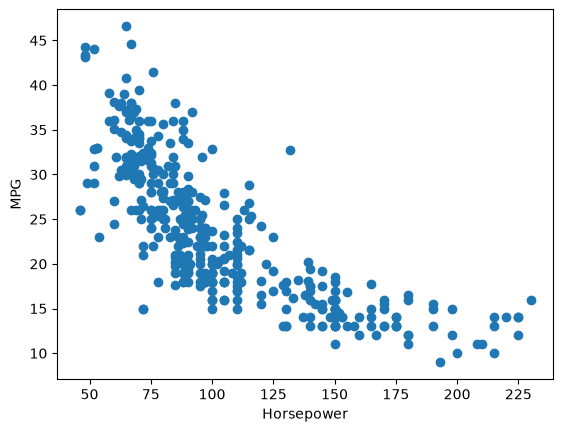

In [9]:
plt.scatter(df["horsepower"], df["mpg"]); plt.xlabel("Horsepower"); plt.ylabel("MPG"); plt.show()

In [10]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [11]:
x_train.shape

(313, 1)

In [12]:
regressor = LinearRegression()

In [13]:
regressor.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-0.16]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['horsepower']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,40.61
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [14]:
y_pred = regressor.predict(x_test)

In [15]:
print(f"R square value : {r2_score(y_test,y_pred)} ")

R square value : 0.5659681822256184 


In [16]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Degree 2
poly_2 = PolynomialFeatures(degree=2)
x_train_poly_2 = poly_2.fit_transform(x_train)

poly_model_2 = LinearRegression()
poly_model_2.fit(x_train_poly_2, y_train)

# Degree 3
poly_3 = PolynomialFeatures(degree=3)
x_train_poly_3 = poly_3.fit_transform(x_train)

poly_model_3 = LinearRegression()
poly_model_3.fit(x_train_poly_3, y_train)

# Compare test R² scores
print("Linear R²:", r2_score(y_test, regressor.predict(x_test)))

print(
    "Polynomial (degree 2) R²:",
    r2_score(y_test, poly_model_2.predict(poly_2.transform(x_test)))
)

print(
    "Polynomial (degree 3) R²:",
    r2_score(y_test, poly_model_3.predict(poly_3.transform(x_test)))
)

Linear R²: 0.5659681822256184
Polynomial (degree 2) R²: 0.6391701147013347
Polynomial (degree 3) R²: 0.6292583325719339


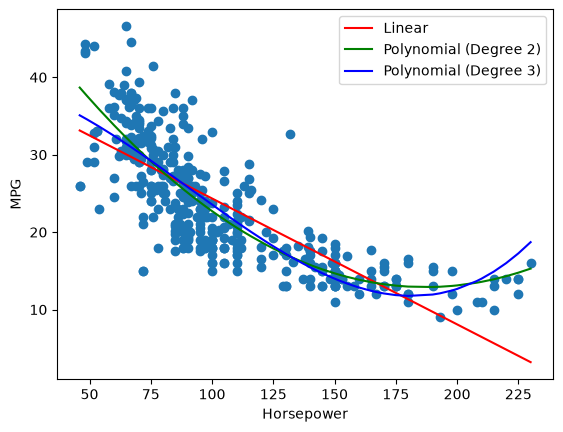

In [18]:
x_sorted = x.sort_values("horsepower")

plt.scatter(x, y)
plt.plot(x_sorted, regressor.predict(x_sorted), color="red", label="Linear")
plt.plot(x_sorted, poly_model_2.predict(poly_2.transform(x_sorted)), color="green", label="Polynomial (Degree 2)")
plt.plot(x_sorted, poly_model_3.predict(poly_3.transform(x_sorted)), color="blue", label="Polynomial (Degree 3)")

plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.legend()
plt.show()

# Polynomial Regression — Complete Notes

## 1. What Is Polynomial Regression?

Polynomial Regression is a supervised Machine Learning technique used to predict a continuous numerical value when the relationship between an input feature and the target may be nonlinear.

Ordinary Linear Regression fits a straight line. Polynomial Regression adds powers of the input feature so the model can learn a curved relationship.

### Our Practice Example: Auto MPG Dataset

We used the Auto MPG dataset to predict a car's fuel efficiency using its horsepower.

- `horsepower` — input feature (`X`)
- `mpg` — target variable (`y`)

**Goal:** Predict a car's MPG based on its horsepower.

## 2. Linear Regression vs Polynomial Regression

### Linear Regression

\[
\hat y=b_0+b_1x
\]

### Polynomial Regression — Degree 2

\[
\hat y=b_0+b_1x+b_2x^2
\]

### Polynomial Regression — Degree 3

\[
\hat y=b_0+b_1x+b_2x^2+b_3x^3
\]

Where:

- \(\hat y\) = predicted MPG.
- \(x\) = horsepower.
- \(b_0\) = intercept.
- \(b_1,b_2,\ldots\) = learned coefficients.

Polynomial Regression is nonlinear in the original input \(x\), but it is still **linear in its coefficients**.

## 3. Load and Clean the Dataset

### Jupyter Notebook — Cell 1: Import libraries

```python
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
```

### Jupyter Notebook — Cell 2: Load the dataset

```python
columns = [
    "mpg", "cylinders", "displacement", "horsepower",
    "weight", "acceleration", "model_year", "origin"
]

df = pd.read_csv(
    "auto-mpg.csv",
    header=None,
    names=columns,
    na_values="?"
)

df["horsepower"] = pd.to_numeric(
    df["horsepower"],
    errors="coerce"
)

df = df.dropna().copy()

print("Dataset shape:", df.shape)
df.head()
```

After cleaning the dataset we used, there are **392 rows**.

We remove rows with missing values because horsepower is our input feature and MPG is our target.

## 4. Select the Feature and Target

### Jupyter Notebook — Cell 3

```python
X = df[["horsepower"]]
y = df["mpg"]

print("X shape:", X.shape)
print("y shape:", y.shape)
```

- `X` contains horsepower values.
- `y` contains actual MPG values.
- Double brackets preserve `X` as a two-dimensional DataFrame.

## 5. Split the Data

### Jupyter Notebook — Cell 4

```python
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
```

The split gives 313 training samples and 79 test samples.

We use the same split for Linear Regression and Polynomial Regression to make their comparison fair.

## 6. Train Linear Regression as a Baseline

### Jupyter Notebook — Cell 5

```python
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

print("Linear Regression R2:",
      r2_score(y_test, linear_pred))
```

Linear Regression fits a straight line between horsepower and MPG.

If the underlying relationship is curved, a straight line may not capture it adequately.

## 7. What Are Polynomial Features?

Polynomial Regression transforms the original input into additional features.

For degree 2:

\[
x\rightarrow[x,x^2]
\]

For degree 3:

\[
x\rightarrow[x,x^2,x^3]
\]

For example, if horsepower is 100, degree 2 creates the features:

\[
[100,10000]
\]

The model learns a coefficient for each generated feature, plus an intercept.

### Using `PolynomialFeatures`

```python
PolynomialFeatures(degree=2, include_bias=False)
```

- `degree=2` includes powers up to \(x^2\).
- `include_bias=False` prevents the transformer from adding a constant column of ones.
- `LinearRegression()` learns the coefficients for the transformed features.

The intercept is still learned by `LinearRegression()`.

## 8. Train Polynomial Regression — Degree 2

### Jupyter Notebook — Cell 6

```python
poly_model = make_pipeline(
    PolynomialFeatures(
        degree=2,
        include_bias=False
    ),
    LinearRegression()
)

poly_model.fit(X_train, y_train)

poly_pred = poly_model.predict(X_test)

print("Polynomial Regression R2:",
      r2_score(y_test, poly_pred))
```

### What happens internally?

1. `PolynomialFeatures` transforms horsepower into horsepower and horsepower squared.
2. `LinearRegression` learns the coefficients for these features.
3. `fit()` trains both steps as a pipeline.
4. `predict()` applies the same transformation to the test data before predicting MPG.

A pipeline helps ensure the training and prediction transformations remain consistent.

## 9. Evaluate Both Models

### Jupyter Notebook — Cell 7

```python
def evaluate_model(name, actual, predicted):
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)

    print(name)
    print("R2:", r2_score(actual, predicted))
    print("MAE:", mean_absolute_error(actual, predicted))
    print("MSE:", mse)
    print("RMSE:", rmse)
    print("-" * 30)


evaluate_model("Linear Regression", y_test, linear_pred)

evaluate_model(
    "Polynomial Regression",
    y_test,
    poly_pred
)
```

Our previously observed results were:

| Model | Test R² |
|---|---:|
| Linear Regression | Approximately 0.566 |
| Polynomial Regression, degree 2 | Approximately 0.639 |

The degree-2 polynomial model performed better on our test split.

These are the results from our earlier practice run; rerunning the notebook verifies the values for the dataset available locally.

### Understanding the evaluation metrics

**R² score:** Measures performance relative to predicting the mean of the test targets. Higher is generally better.

**MAE:** Average absolute prediction error in MPG.

**MSE:** Average squared prediction error.

**RMSE:** Square root of MSE, expressed in MPG.

When comparing models on the same test set, lower error metrics and a higher R² are generally preferable.

## 10. Visualize Both Models

### Jupyter Notebook — Cell 8

```python
x_sorted = X.sort_values("horsepower")

linear_line = linear_model.predict(x_sorted)
poly_line = poly_model.predict(x_sorted)

plt.scatter(
    X["horsepower"],
    y,
    alpha=0.5,
    label="Actual data"
)

plt.plot(
    x_sorted["horsepower"],
    linear_line,
    color="red",
    label="Linear Regression"
)

plt.plot(
    x_sorted["horsepower"],
    poly_line,
    color="green",
    label="Polynomial Regression (degree 2)"
)

plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.show()
```

### Interpreting the graph

- Scatter points represent actual observations.
- The red line represents Linear Regression.
- The green curve represents Polynomial Regression.
- The polynomial curve can capture curvature that a straight line cannot.

The polynomial model is not guaranteed to be better for every dataset.

## 11. Understanding Polynomial Degree

The degree determines the highest power of the input feature included in the model.

| Degree | Model | Behavior |
|---|---|---|
| 1 | \(b_0+b_1x\) | Straight line |
| 2 | \(b_0+b_1x+b_2x^2\) | Can curve upward or downward |
| 3 | \(b_0+b_1x+b_2x^2+b_3x^3\) | Can represent more complex curvature |
| Higher degrees | Includes higher powers | More flexibility and greater overfitting risk |

A higher degree does not automatically mean better predictions.

## 12. Experiment with Different Degrees

### Jupyter Notebook — Cell 9

```python
for degree in [1, 2, 3, 4, 5]:
    model = make_pipeline(
        PolynomialFeatures(
            degree=degree,
            include_bias=False
        ),
        LinearRegression()
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    print(f"Degree: {degree}")
    print("Train R2:", r2_score(y_train, train_pred))
    print("Test R2:", r2_score(y_test, test_pred))
    print("-" * 30)
```

### How should we select the degree?

- A low degree may underfit the relationship.
- A high degree may overfit noise.
- Training performance alone is insufficient.
- Use validation data or cross-validation to select the degree.
- Evaluate the selected model on the test set only after choosing it.

For a rigorous experiment, do not repeatedly select the best degree based on test-set performance.

## 13. Underfitting and Overfitting

### Underfitting

The model is too simple to capture the underlying pattern.

For example, a straight line may not adequately describe a curved relationship between horsepower and MPG.

### Overfitting

The model fits noise or peculiarities in the training set rather than the general pattern.

High-degree polynomial models can fluctuate dramatically, especially near the boundaries of the training data.

The goal is to find a model that captures meaningful patterns and generalizes to unseen data.

## 14. Does Polynomial Regression Use Gradient Descent?

Polynomial Regression is a combination of **feature transformation and regression**, not a separate optimization algorithm.

In our pipeline:

```python
PolynomialFeatures(degree=2, include_bias=False)
LinearRegression()
```

- `PolynomialFeatures` generates the polynomial features.
- `LinearRegression` learns their coefficients using Ordinary Least Squares by default.

Gradient Descent can also optimize a polynomial regression model, but the standard scikit-learn `LinearRegression()` estimator does not use iterative Gradient Descent for fitting.

## 15. Advantages and Limitations

### Advantages

- Captures curved relationships.
- Easy to implement using scikit-learn.
- Can improve predictions when the relationship is nonlinear.
- Retains a familiar regression framework.

### Limitations

- High-degree models can overfit.
- Higher powers can create numerical scaling issues.
- Extrapolation beyond the training range can be unreliable.
- More polynomial features increase model complexity.

## 16. Common Interview Questions

**1. What is Polynomial Regression?**

A regression technique that adds powers of input features to model nonlinear relationships.

**2. Why is Polynomial Regression still considered linear in its parameters?**

Because the model is a linear combination of learned coefficients, even though the input features include powers such as \(x^2\) and \(x^3\).

**3. What does `PolynomialFeatures(degree=2)` do?**

For one input feature, it creates the feature and its square. With `include_bias=False`, it does not add a constant column.

**4. Why use a pipeline?**

It applies the same feature transformation consistently during training and prediction.

**5. Does a higher degree always improve test performance?**

No. Higher degrees can overfit.

**6. What is the main difference between Linear and Polynomial Regression?**

Linear Regression uses the original features in a linear model. Polynomial Regression adds powered features to represent curved relationships.

**7. Does Polynomial Regression require Gradient Descent?**

No. It can use Ordinary Least Squares or another suitable optimization algorithm.

**8. Why can polynomial models extrapolate poorly?**

Higher powers can grow rapidly outside the training range, producing unrealistic predictions.

## 17. Quick Revision

- Dataset: Auto MPG.
- Input: `horsepower`.
- Target: `mpg`.
- Cleaned dataset: 392 rows.
- Training set: 313 rows.
- Test set: 79 rows.
- Linear Regression test R²: approximately 0.566.
- Degree-2 Polynomial Regression test R²: approximately 0.639.
- `PolynomialFeatures` generates powered features.
- `make_pipeline()` combines transformation and model fitting.
- Degree controls model flexibility.
- Higher degrees can overfit.
- Select complexity using validation data and reserve the test set for final evaluation.
